# 00 · Setup & Data — official Citeseer TAG, sized to fit a CPU time budget

CMUCL: *Text-Attributed Graph Anomaly Detection via Multi-Scale Cross- and Uni-Modal Contrastive Learning* (arXiv:2508.00513). Official code: https://github.com/yimingxu24/CMUCL — fetched at runtime, never copied here.

In [4]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")      # Windows: avoid the duplicate-OpenMP abort that kills the kernel
import faulthandler; faulthandler.enable()
import sys, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx
from cmucl_nb import common as C

DATASET = os.environ.get("CMUCL_DATASET", "Citeseer")
N_NODES = os.environ.get("CMUCL_N_NODES", "auto")           # "auto" = fit the time budget | "full" | an integer
BUDGET_MIN = float(os.environ.get("CMUCL_BUDGET_MIN", 45))  # target for the whole pipeline (notebooks 00-05)
cfg = C.make_config(DATASET)
for f in ["init_state.pt", "probe.pt", "trained_state.pt", "history.json", "scores.csv", "metrics.json",
          "stage02.json", "stage03.json", "dataset.pkl"]:      # stale outputs of a previous run
    (C.ART / f).unlink(missing_ok=True)
print(cfg)

{'lr': 0.0002, 'epoch_num': 2, 'gamma': 0.005, 'batch_size': 64, 'neigh_num': 3, 'scale': 0.07, 'gnn_layers': 2, 'gnn_input': 768, 'gnn_hid': 128, 'gnn_output': 128, 'context_length': 128, 'embed_dim': 128, 'transformer_heads': 8, 'transformer_layers': 12, 'transformer_width': 512, 'vocab_size': 49408, 'rounds': 256, 'seed': 1, 'edge_coef': 10, 'optim': 0, 'norm': 0, 'reg': 0, 'drop_prob': 0.2, 'aggregation_times': 2, 'gpu': 0, 'dataset': 'Citeseer'}


In [5]:
C.fetch_official_code()
import torch, torch_geometric
print("official files:", sorted(p.name for p in C.OFFICIAL.iterdir()))
C.set_cpu_threads()
print("torch", torch.__version__, "| torch_geometric", torch_geometric.__version__, "| cuda:", torch.cuda.is_available(), "| torch threads:", torch.get_num_threads())

official files: ['.git', 'README.md', 'bpe_simple_vocab_16e6.txt.gz', 'data.py', 'main_train.py', 'model.py', 'pipeline.svg', 'simple_tokenizer.py']
torch 2.10.0+cpu | torch_geometric 2.8.1 | cuda: False | torch threads: 4


In [6]:
full = C.load_official_dataset(DATASET)                      # raises a clear error if the official files are missing
n_full, a_full = full["n"], int(full["labels"].sum())
e_full = full["n_offdiag_edges"]
print(f"{DATASET}: nodes={n_full}, anomalies={a_full}, feature dim={full['feats'].shape[1]}")
print(f"adjacency matrix: nnz={full['nnz']} | self-loops={full['n_selfloops']} | real undirected edges (off-diagonal)={full['n_offdiag_edges']}")
if DATASET == "Citeseer":
    exp = C.EXPECTED_CITESEER
    print("official README says:", exp)
    if (n_full, a_full, full["nnz"]) != (exp["nodes"], exp["anomalies"], exp["edges"]):   # the README 'edges' = nnz of the adjacency matrix
        print("WARNING: statistics differ from the official table -> make sure these are the official Citeseer files.")
    else: print("OK: statistics match the official dataset table.")

Citeseer: nodes=3186, anomalies=128, feature dim=768
adjacency matrix: nnz=3432 | self-loops=3186 | real undirected edges (off-diagonal)=198
official README says: {'nodes': 3186, 'edges': 3432, 'anomalies': 128}
OK: statistics match the official dataset table.


In [7]:
if N_NODES == "full":
    n_keep, est = n_full, None
elif N_NODES == "auto":
    print("Timing the official-size text encoder on a small micro-batch and extrapolating (safe for RAM) ...", flush=True)
    t = C.benchmark_batch_times(cfg)
    n_keep, est = C.plan_nodes(cfg, n_full, t, BUDGET_MIN)
    print(f"\ntraining step: {t['t_train']:.1f}s | embedding batch (inference): {t['t_embed']:.1f}s")
    print(f"=> {n_keep} of {n_full} nodes, estimated whole pipeline ~ {est:.0f} min (budget {BUDGET_MIN:.0f} min)")
    full_est = C.estimate_minutes(n_full, cfg, t); print(f"(for reference: the FULL graph would take ~ {full_est:.0f} min on this CPU)")
else:
    n_keep, est = int(N_NODES), None

Timing the official-size text encoder on a small micro-batch and extrapolating (safe for RAM) ...
  available RAM: 4.0 GB | torch threads: 4
  threads now: 4 | checkpointing: True
  micro-batch (16 seqs) fwd+bwd 1/2: 8.8s  (warm-up, discarded)
  micro-batch (16 seqs) fwd+bwd 2/2: 9.0s

training step: 145.3s | embedding batch (inference): 9.1s
=> 384 of 3186 nodes, estimated whole pipeline ~ 41 min (budget 45 min)
(for reference: the FULL graph would take ~ 295 min on this CPU)


In [8]:
ds = C.subset_snowball(full, n_keep, seed=0)
n = ds["n"]; n_edges = ds["edge_index"].shape[1] // 2
deg = np.bincount(ds["edge_index"][0], minlength=n)
n_words = np.array([len(str(t).split()) for t in ds["texts"]])
def _se(d): return int((d['edge_index'][0] == d['edge_index'][1]).sum()), int((d['edge_index'][0] != d['edge_index'][1]).sum() // 2)
sl, ed = _se(ds)
stats = pd.DataFrame({"full (official)": [n_full, full['n_selfloops'], e_full, a_full, f"{100*full['labels'].mean():.2f}%", f"{np.mean([len(str(t).split()) for t in full['texts']]):.1f}"],
                      "used here": [n, sl, ed, int(ds["labels"].sum()), f"{100*ds['labels'].mean():.2f}%", f"{n_words.mean():.1f}"]},
                     index=["nodes", "self-loops", "real undirected edges", "anomalies", "anomaly rate", "avg doc length (words)"])
display(stats)
if ds["labels"].sum() < 10: print("WARNING: fewer than 10 anomalies -> AUC/AP will be very noisy.")
cfg.update(n_full=int(n_full), n_nodes=int(n), estimated_minutes=None if est is None else float(est))
C.save_config(cfg)

,full (official),used here
nodes,3186,384
self-loops,3186,384
real undirected edges,198,75
anomalies,128,19
anomaly rate,4.02%,4.95%
avg doc length (words),151.4,151.1


In [9]:
A_deg = np.bincount(full["edge_index"][0][full["edge_index"][0] != full["edge_index"][1]], minlength=n_full)
lab = full["labels"]
print(f"nodes with at least one REAL neighbour: {(A_deg > 0).sum()} / {n_full}")
print(f"  among normal nodes   : {((A_deg > 0) & (lab == 0)).sum()} / {(lab == 0).sum()}")
print(f"  among anomalous nodes: {((A_deg > 0) & (lab == 1)).sum()} / {(lab == 1).sum()}")
print("=> most nodes have only a self-loop: for them the 'neighbourhood context' is the node itself, and structural anomalies"
      " (the injected cliques / random edges) are almost the only nodes with real edges.")

nodes with at least one REAL neighbour: 210 / 3186
  among normal nodes   : 146 / 3058
  among anomalous nodes: 64 / 128
=> most nodes have only a self-loop: for them the 'neighbourhood context' is the node itself, and structural anomalies (the injected cliques / random edges) are almost the only nodes with real edges.


<div dir="rtl" style="text-align:right">

> **نکته‌ی کد رسمی** (`data.py`): فقط گره‌هایی که حداقل یک یال دارند وارد `DataHelper` می‌شوند. در زیرگراف، گره‌های بدون یال را از ابتدا حذف کرده‌ام (آمار بالا بعد از حذف است).

</div>

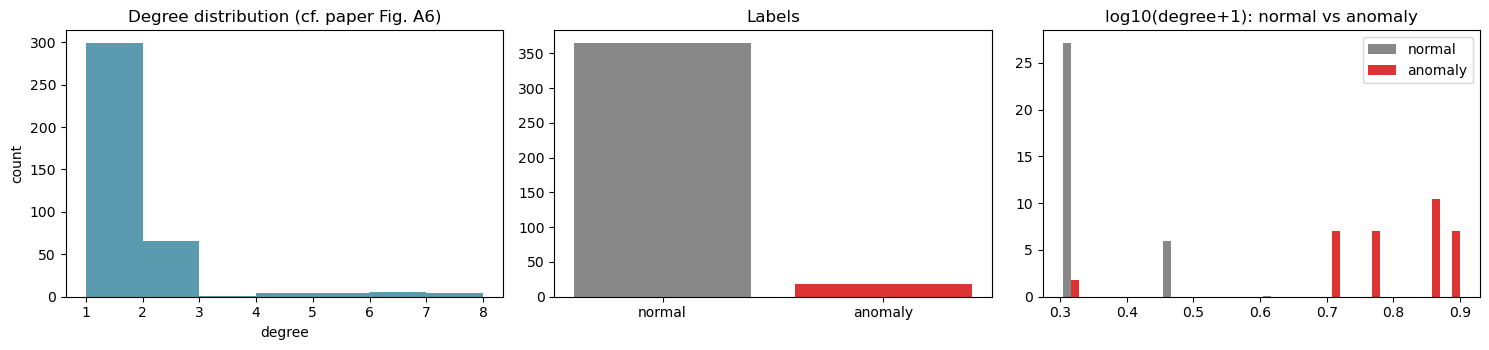

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
d = deg[deg > 0]
ax[0].hist(d, bins=range(1, min(d.max(), 60) + 2), color="#5b9bb0"); ax[0].set_title("Degree distribution (cf. paper Fig. A6)")
ax[0].set_xlabel("degree"); ax[0].set_ylabel("count")
ax[1].bar(["normal", "anomaly"], [(ds["labels"] == 0).sum(), (ds["labels"] == 1).sum()], color=["#888", "#d33"]); ax[1].set_title("Labels")
ax[2].hist([np.log10(deg[ds["labels"] == 0] + 1), np.log10(deg[ds["labels"] == 1] + 1)], bins=20, label=["normal", "anomaly"],
           color=["#888", "#d33"], density=True); ax[2].legend(); ax[2].set_title("log10(degree+1): normal vs anomaly")
plt.tight_layout(); C.savefig("00_data_overview"); plt.show()

<div dir="rtl" style="text-align:right">

## متن هر گره
هر گره یک متن خام دارد ($t_i$). در ناهنجاری‌های *contextual* مقاله (Appendix A) بخشی از متن با متن گره‌ای نامشابه جایگزین/وارد شده است:

</div>

In [11]:
def show(i, k=350): print(f"[node {i} | label={ds['labels'][i]} | original index {ds['orig_index'][i]}]\n{str(ds['texts'][i])[:k]}\n")
show(int(np.where(ds["labels"] == 0)[0][0]))
for i in np.where(ds["labels"] == 1)[0][:2]: show(int(i))

[node 0 | label=0 | original index 1]
Decomposition in Data Mining: An Industrial Case Study Data mining offers tools for discovery of relationships, patterns, and knowledge in large databases. The knowledge extraction process is computationally complex and therefore a subset of all data is normally considered for mining. In this paper, numerous methods for decomposition of data sets a

[node 46 | label=1 | original index 460]
Temporal Statement Modifiers A wide range of database applications manage time-varying data. Many temporal query languages have been proposed, each one the result of many carefully made yet subtly interacting design decisions. In this article we advocate a different approach to articulating a set of requirements, or desiderata, that directly imply 

[node 71 | label=1 | original index 587]
Finding the Most Similar Documents across Multiple Text Databases In this paper, we present a methodology for finding the n most similar documents across multiple text database

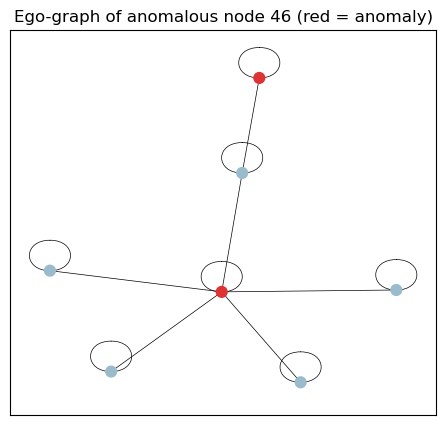

In [12]:
cand = [i for i in np.where(ds["labels"] == 1)[0] if deg[i] > 0]
center = int(cand[0])
G = nx.Graph(); G.add_edges_from(ds["edge_index"].T.tolist())
nodes = list(nx.ego_graph(G, center, radius=2).nodes)[:70]
H = G.subgraph(nodes)
colors = ["#d33" if ds["labels"][v] == 1 else "#9bc" for v in H.nodes]
plt.figure(figsize=(5.5, 5)); nx.draw_networkx(H, node_color=colors, node_size=60, with_labels=False, width=.5)
plt.title(f"Ego-graph of anomalous node {center} (red = anomaly)"); C.savefig("00_ego_graph"); plt.show()

In [13]:
C.save_dataset(ds)
print("saved:", C.ART / "dataset.pkl")

saved: D:\ارشد علم داده\proposal\Desk\Text-Attributed Graph Anomaly Detection via\CMUCL-Notebooks\artifacts\dataset.pkl
